In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import find_peaks
import datetime
import multiprocess as mp
import pickle
sys.path.insert(0, "./cellular_cycle") # add path to the model

from cell_cycle_death_model import model
from model_fxns import *
from pysb.simulator import ScipyOdeSimulator

In [2]:
# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()
    
ODE_DIR = Path(Path.home(),'ECM_mod_output/ODE_output')
if not ODE_DIR.exists():
    ODE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [3]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ './model_data/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

Stress
b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [4]:
t = np.linspace(0, 1000, 100001)
t_0 = np.linspace(0, 2000, 200001)
# t = np.linspace(0, 20000, 200001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 1
model.parameters['ERK'].value = 1
model.parameters['FAK'].value = 0.6

In [5]:
with open(os.getcwd()+ './fit_data/pso/frac_prolif_parameters_pso.pkl', 'rb') as f:
    frac_prolif_parameters_pso = pickle.load(f)

In [6]:
new_param_pso_sort = frac_prolif_parameters_pso.sort_values([('cost', 'total cost likelihood')])
new_params = new_param_pso_sort['model parameters']

In [7]:
# Importing the parameters:
ii = 0
for key in new_params.keys():
    try:
        if model.parameters[key].value != new_params[key].iloc[ii]:
            model.parameters[key].value = new_params[key].iloc[ii]
    except:
        print(key)
model.parameters['omega'].value = 200

In [8]:
initial_concentrations = pd.read_csv(os.getcwd() + './model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

BAXm_0
BCL2_0


In [9]:
integrator_options = {
    "rtol": 1e-12,
    "atol": 1e-12
}

In [10]:
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python', integrator_options=integrator_options).run() #deterministic simulation

In [11]:
y_out = sim_ode.observables

<Axes: xlabel='Time (h)', ylabel='Concentration'>

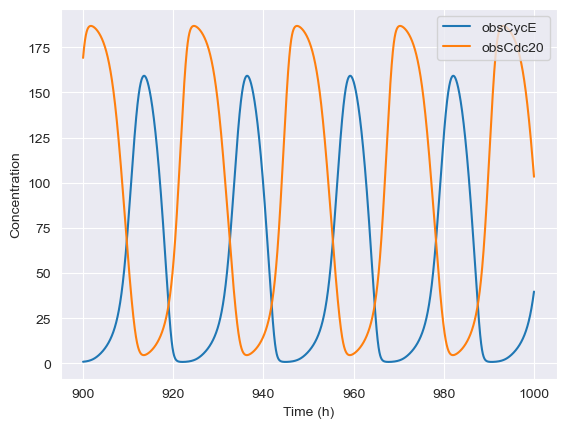

In [12]:
### Define observables to plot (will be reused)

observables=['obsCycE','obsCdc20']; #plot Cyclin E, Cdc20 and Cyclin A

### Plot ODE simulation output of new model file


plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(90000,100000), legend=True)

In [13]:
##ERL
treatment = 'ERL'
FAKs = list(np.linspace(0.4,0.6,500))
tmp = list(np.linspace(0.6,1,500))
FAKs.extend(tmp)

AKTs = list(np.linspace(0.3,0.6,500))
tmp = [0.6]*500
AKTs.extend(tmp)
ERKs = [0.2]*1000
vals=np.linspace(0,999,1000)
conds = [(AKT, ERK, FAK, val) for AKT, ERK, FAK, val in zip(AKTs, ERKs, FAKs, vals)]

In [26]:
def run_odes(AKT, ERK, FAK, val, treatment=treatment, np=np, model=model, ScipyOdeSimulator=ScipyOdeSimulator, find_peaks=find_peaks, Path=Path, integrator_options=integrator_options):
    model.parameters['AKT'].value = AKT
    model.parameters['ERK'].value = ERK
    model.parameters['FAK'].value = FAK
    t = np.linspace(0, 1000, 100001)    

    sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python', integrator_options=integrator_options).run()
    y_out = sim_ode.observables

    peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence = 0.6, distance = 10)
    peaks_half = peaks_cdc[peaks_cdc < len(y_out)/2]
    peaks_half2 = peaks_cdc[peaks_cdc > len(y_out)/2]
    
    if len(peaks_cdc) > 7:
        variable_range=y_out[peaks_cdc[-6]:peaks_cdc[-1]]
    else:
        variable_range = y_out[90000:100000]        
    
    tmp = int(val)
    filename = Path(Path.home(), f'ECM_mod_output/ODE_output/{treatment}_range_{tmp:03}.csv')
    
    np.savetxt(filename, variable_range, delimiter=',')

    if len(peaks_half2) > 0:
        IMTs = [t[y] - t[x] for x, y in zip(peaks_half2, peaks_half2[1:])]
        meanIMT = sum(IMTs) / len(IMTs)
    else:
        meanIMT = 0

    
        
    return meanIMT
                
        

In [27]:
conds = [(AKT, ERK, FAK, val) for AKT, ERK, FAK, val in zip(AKTs, ERKs, FAKs, vals)]

In [28]:
import time

In [30]:
start = time.time()
with mp.Pool(processes = 14) as p:
    results = p.starmap(run_odes, conds)
end = time.time()
print(end - start)

1294.6431889533997


In [31]:
filename = Path(Path.home(), f'ECM_mod_output/ODE_output/{treatment}_IMT.csv')
np.savetxt(filename, results, delimiter=',')

In [32]:
##DMSO
treatment = 'DMSO'
FAKs = list(np.linspace(0.4,0.6,500))
tmp = list(np.linspace(0.6,1,500))
FAKs.extend(tmp)
AKTs = list(np.linspace(0.6,1,500))
tmp = [1]*500
AKTs.extend(tmp)
ERKs = [1]*1000

In [33]:
conds = [(AKT, ERK, FAK, val) for AKT, ERK, FAK, val in zip(AKTs, ERKs, FAKs, vals)]

In [ ]:
start = time.time()
with mp.Pool(processes = 14) as p:
    results = p.starmap(run_odes, conds)
end = time.time()
print(end - start)

In [47]:
filename = Path(Path.home(), f'ECM_mod_output/ODE_output/{treatment}_IMT_05.csv')
np.savetxt(filename, results, delimiter=',')

In [143]:
IMTs = [results[ii][1] for ii in range(len(results))]
trajs = [results[ii][0] for ii in range(len(results))]


In [163]:
all_runs = []
for ii in range(len(results)):
    tmp_run = []
    for jj in range(len(results[ii][0])):
        tmp_run.append(list(results[ii][0][jj]))
    all_runs.append(np.array(tmp_run))

In [167]:
test=np.asarray(all_runs, dtype="object")

In [162]:
test[0]

array([1.08876259e+01, 1.19897715e+02, 4.27366931e+02, 8.94778180e+00,
       1.91052218e+02, 9.15151515e+01, 2.20281550e+01, 2.36401528e+01,
       1.66324027e+02, 3.63338479e+00, 1.40768933e+00, 1.06392235e+02,
       1.46288987e+00, 2.95718785e+00, 6.29823327e+00, 3.03696313e+01,
       8.20435547e+01, 1.05072951e+01, 1.49418184e+02, 1.82927278e+02,
       1.60285251e+01, 1.91773278e-01, 1.09088227e+02, 4.46145097e-02,
       1.82028659e+02])

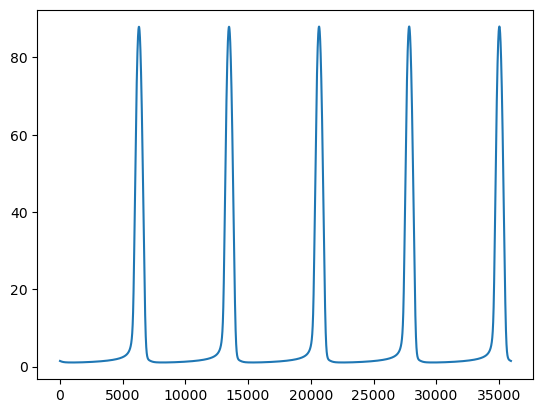

In [84]:
plt.plot(tmp['obsCycE'])

In [ ]:
start = time.time()
with mp.Pool(processes = 12) as p:
    results = p.starmap(run_odes, [(AKTs[0], ERKs[0], FAKs[0], vals[0]),
                                    (AKTs[49], ERKs[49], FAKs[49], vals[49]),
                                    (AKTs[99], ERKs[99], FAKs[99], vals[99])])
end = time.time()
print(end - start)

In [ ]:
np.savetxt(f'C:/Users/olesk/ECM_mod_output/odes/erl_range_1_22_IMT.csv',
               results, delimiter=',')

In [ ]:
all_imts = []
all_ode_erl = []
for result in results:
    all_ode_erl.append(result[0])
    all_imts.append(result[1])

In [ ]:
FAKs = list(np.linspace(0.4,0.6,50))
tmp = list(np.linspace(0.6,1,50))
FAKs.extend(tmp)

AKTs = list(np.linspace(0.3,0.6,50))
tmp = [0.6]*50
AKTs.extend(tmp)
ERKs = [0.2]*100